# Entry Door Slot Demo

这个 notebook 专门展示 semantic grid 边界洞口：`Entry` 是 BFS/reachability 起点，不是 RoadBand，也不参与连续冲突评分。

In [1]:
import os
import sys

def find_order_analyzer_parent(start=None):
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, "features")) and os.path.isdir(os.path.join(current, "OCTA_toolbox-master")):
            return os.path.abspath(os.path.join(current, os.pardir))
        if os.path.isdir(os.path.join(current, "order_analyzer")) and os.path.isdir(os.path.join(current, "order_analyzer", "features")):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise RuntimeError(f"Cannot find order_analyzer parent from cwd={os.getcwd()}")
        current = parent

project_parent = find_order_analyzer_parent()
if project_parent not in sys.path:
    sys.path.insert(0, project_parent)

from order_analyzer import OrderAnalyzer, TableGrid, TableTemplate
from order_analyzer.features.affordance import scene_grid_overlay_svg
from IPython.display import SVG, display

print("added path:", project_parent)
print("cwd:", os.getcwd())

added path: D:\PROJECTS\understandOtherPackage
cwd: D:\PROJECTS\understandOtherPackage\order_analyzer


In [2]:
LAYOUT_SIZE = (300, 300)
RESOLUTION = 20

standard_table = TableTemplate(
    size=(40, 20),
    type_id="table.default",
    affordance={"usable_edges": ("right",), "edge_depth": {"right": 20}},
    aisle={"min_width": 80},
)

# Baseline keeps the old behavior: no explicit entry means the whole left boundary is open.
fallback_grid = TableGrid(3, 3, fill=standard_table)
fallback_layout = fallback_grid.to_layout()
fallback_report = OrderAnalyzer(
    fallback_layout,
    fallback_layout,
    layout_size=LAYOUT_SIZE,
    fit_to_layout=True,
).report(
    features=("positions",),
    include_affordance=True,
    affordance_options={"width": LAYOUT_SIZE[0], "height": LAYOUT_SIZE[1], "resolution": RESOLUTION},
)

print("fallback entries:", fallback_report["aisle"]["entries"])

fallback entries: [{'id': 'left-boundary', 'edge': 'left', 'entry_cells': 15, 'source': 'default'}]


In [3]:
# Door-slot entry: open only the middle row band on the left boundary.
door_grid = TableGrid(3, 3, fill=standard_table)
door_grid.entry(edge="left", index=1, width=80, id="main_door")
door_layout = door_grid.to_layout()

door_analyzer = OrderAnalyzer(
    door_layout,
    door_layout,
    layout_size=LAYOUT_SIZE,
    fit_to_layout=True,
)
door_report = door_analyzer.report(
    features=("positions",),
    include_affordance=True,
    affordance_options={"width": LAYOUT_SIZE[0], "height": LAYOUT_SIZE[1], "resolution": RESOLUTION},
)

print("door entries:", door_report["aisle"]["entries"])
print("entry sampled cells:", sum(sum(row) for row in door_report["aisle"]["debug"]["entries"]))

door entries: [{'id': 'main_door', 'edge': 'left', 'entry_cells': 5, 'source': 'explicit'}]
entry sampled cells: 5


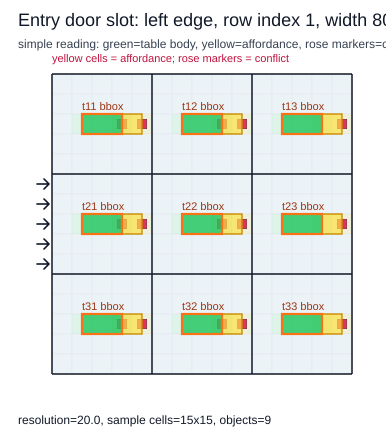

In [4]:
# Overlay reading: arrow = BFS start door; pale green = reachable sampled cells.
# The door itself is continuous EntryBand geometry sampled only for reachability.
door_scene = door_analyzer._build_scene_model()
door_svg = scene_grid_overlay_svg(
    scene=door_scene,
    report=door_report,
    layout_size=LAYOUT_SIZE,
    resolution=RESOLUTION,
    title="Entry door slot: left edge, row index 1, width 80",
)
display(SVG(door_svg))

In [5]:
# Occupied door check: a large table in the middle-left cell covers the door cells, so BFS gets zero starts.
blocked_template = TableTemplate(size=(100, 100), type_id="table.default")
blocked_grid = TableGrid(3, 3, fill=blocked_template)
blocked_grid.entry(edge="left", index=1, width=80, id="blocked_door")
blocked_layout = blocked_grid.to_layout()
blocked_report = OrderAnalyzer(
    blocked_layout,
    blocked_layout,
    layout_size=LAYOUT_SIZE,
    fit_to_layout=True,
).report(
    features=("positions",),
    include_affordance=True,
    affordance_options={"width": LAYOUT_SIZE[0], "height": LAYOUT_SIZE[1], "resolution": RESOLUTION},
)

print("blocked door entries:", blocked_report["aisle"]["entries"])
print("blocked entry sampled cells:", sum(sum(row) for row in blocked_report["aisle"]["debug"]["entries"]))

blocked door entries: [{'id': 'blocked_door', 'edge': 'left', 'entry_cells': 0, 'source': 'explicit'}]
blocked entry sampled cells: 0
